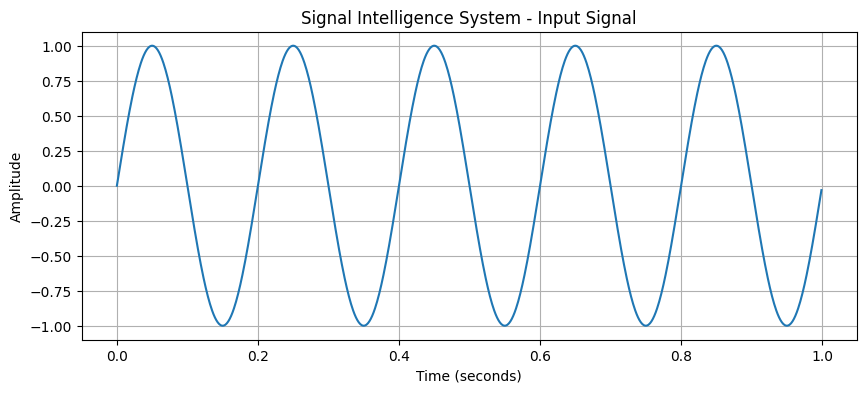

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# AI-Based Signal Intelligence System
fs = 1000
t = np.arange(0, 1, 1/fs)
frequency = 5

signal = np.sin(2 * np.pi * frequency * t)

plt.figure(figsize=(10, 4))
plt.plot(t, signal)
plt.title("Signal Intelligence System - Input Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

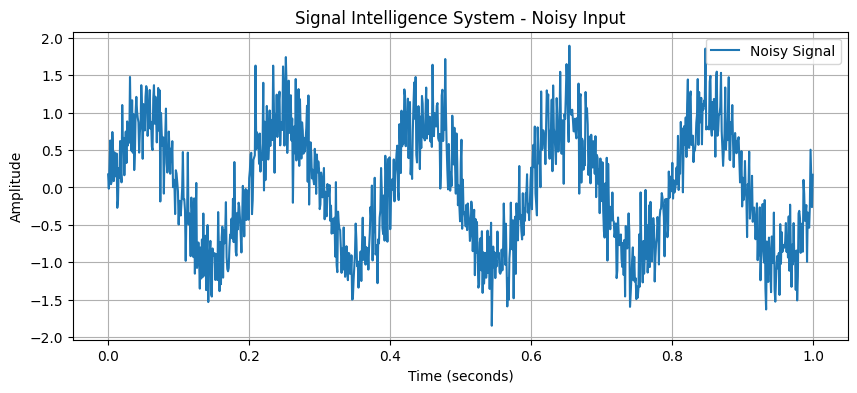

In [2]:
# Step 2: Add noise to the signal
np.random.seed(42)

noise = np.random.normal(0, 0.35, len(signal))
noisy_signal = signal + noise

plt.figure(figsize=(10, 4))
plt.plot(t, noisy_signal, label="Noisy Signal")
plt.title("Signal Intelligence System - Noisy Input")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

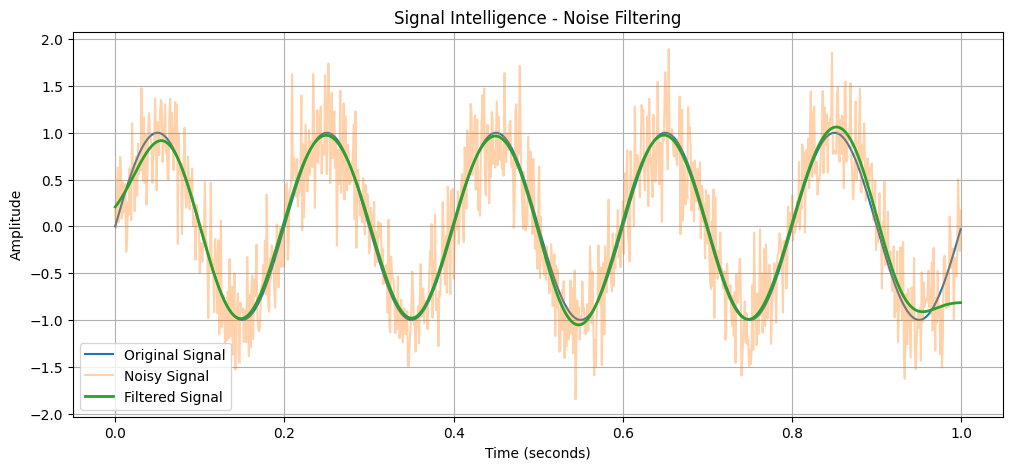

In [3]:
from scipy.signal import butter, filtfilt

# Design a low-pass digital filter
cutoff_frequency = 10
nyquist_frequency = fs / 2

b, a = butter(
    4,
    cutoff_frequency / nyquist_frequency,
    btype="low"
)

cleaned_signal = filtfilt(b, a, noisy_signal)

# Compare original, noisy, and filtered signals
plt.figure(figsize=(12, 5))
plt.plot(t, signal, label="Original Signal")
plt.plot(t, noisy_signal, alpha=0.35, label="Noisy Signal")
plt.plot(t, cleaned_signal, label="Filtered Signal", linewidth=2)

plt.title("Signal Intelligence - Noise Filtering")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

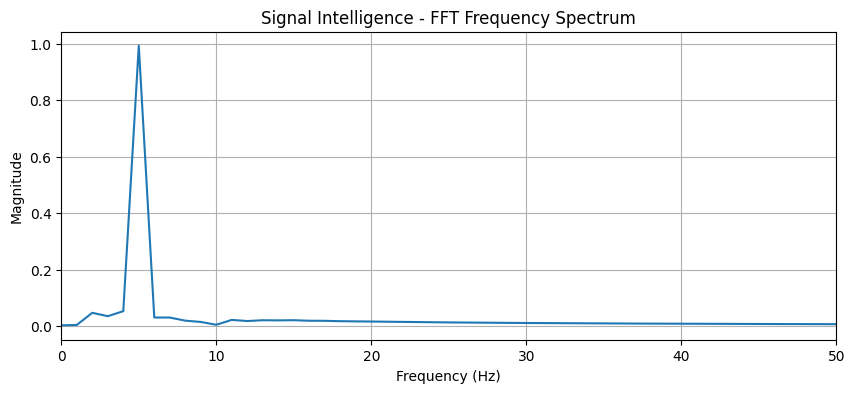

Detected dominant frequency: 5.00 Hz


In [4]:
# Step 4: FFT Frequency Analysis

N = len(cleaned_signal)

frequencies = np.fft.rfftfreq(N, d=1/fs)
spectrum = np.abs(np.fft.rfft(cleaned_signal)) * 2 / N

# Ignore the zero-frequency component
peak_index = np.argmax(spectrum[1:]) + 1
dominant_frequency = frequencies[peak_index]

plt.figure(figsize=(10, 4))
plt.plot(frequencies, spectrum)
plt.xlim(0, 50)
plt.title("Signal Intelligence - FFT Frequency Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.grid(True)
plt.show()

print(f"Detected dominant frequency: {dominant_frequency:.2f} Hz")

In [6]:
from scipy.signal import square, sawtooth
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

# Create training data for 3 signal types
X = []
y = []

for label, kind in enumerate(["sine", "square", "triangle"]):
    for _ in range(200):
        freq = np.random.uniform(3, 15)
        phase = np.random.uniform(0, 2*np.pi)
        amp = np.random.uniform(0.7, 1.3)

        tt = np.arange(0, 1, 1/fs)
        angle = 2*np.pi*freq*tt + phase

        if kind == "sine":
            sig = amp * np.sin(angle)
        elif kind == "square":
            sig = amp * square(angle)
        else:
            sig = amp * sawtooth(angle, width=0.5)

        sig += np.random.normal(0, 0.15, len(tt))

        features = [
            np.mean(sig),
            np.std(sig),
            np.sqrt(np.mean(sig**2)),
            np.max(sig),
            np.min(sig),
            np.mean(np.abs(sig))
        ]

        X.append(features)
        y.append(kind)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("AI Signal Classifier trained successfully!")
print(f"Test accuracy: {accuracy_score(y_test, predictions)*100:.2f}%")
print(classification_report(y_test, predictions))

AI Signal Classifier trained successfully!
Test accuracy: 98.33%
              precision    recall  f1-score   support

        sine       0.97      0.97      0.97        40
      square       1.00      1.00      1.00        40
    triangle       0.97      0.97      0.97        40

    accuracy                           0.98       120
   macro avg       0.98      0.98      0.98       120
weighted avg       0.98      0.98      0.98       120



AI Prediction: square
Actual Signal: square
Prediction Correct: True


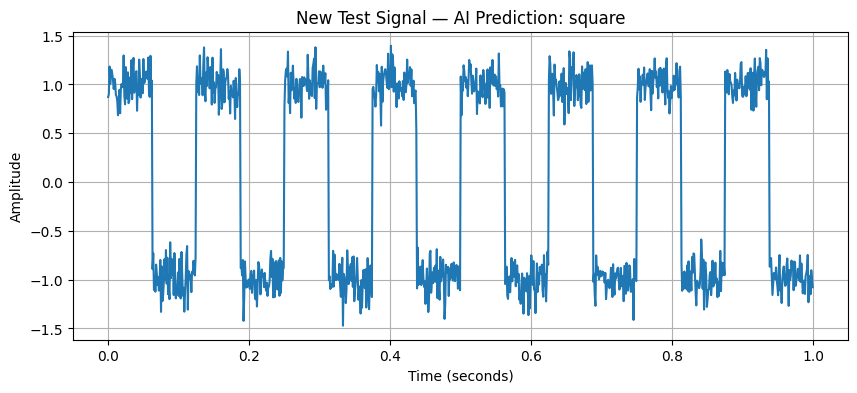

In [7]:
# Test the trained AI on a new signal

test_frequency = 8
test_time = np.arange(0, 1, 1/fs)

new_signal = square(2 * np.pi * test_frequency * test_time)
new_signal = new_signal + np.random.normal(0, 0.15, len(test_time))

features = [[
    np.mean(new_signal),
    np.std(new_signal),
    np.sqrt(np.mean(new_signal**2)),
    np.max(new_signal),
    np.min(new_signal),
    np.mean(np.abs(new_signal))
]]

prediction = model.predict(features)[0]

print("AI Prediction:", prediction)
print("Actual Signal: square")
print("Prediction Correct:", prediction == "square")

plt.figure(figsize=(10, 4))
plt.plot(test_time, new_signal)
plt.title(f"New Test Signal — AI Prediction: {prediction}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

AI Prediction: square
Actual Signal: square
Prediction Correct: True


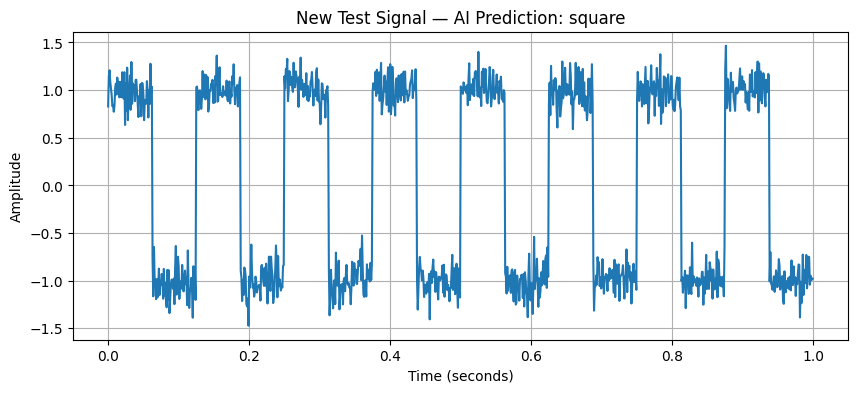

In [8]:
# Test the trained AI on a new signal

test_frequency = 8
test_time = np.arange(0, 1, 1/fs)

new_signal = square(2 * np.pi * test_frequency * test_time)
new_signal = new_signal + np.random.normal(0, 0.15, len(test_time))

features = [[
    np.mean(new_signal),
    np.std(new_signal),
    np.sqrt(np.mean(new_signal**2)),
    np.max(new_signal),
    np.min(new_signal),
    np.mean(np.abs(new_signal))
]]

prediction = model.predict(features)[0]

print("AI Prediction:", prediction)
print("Actual Signal: square")
print("Prediction Correct:", prediction == "square")

plt.figure(figsize=(10, 4))
plt.plot(test_time, new_signal)
plt.title(f"New Test Signal — AI Prediction: {prediction}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

AI Prediction: square
Actual Signal: square
Prediction Correct: True


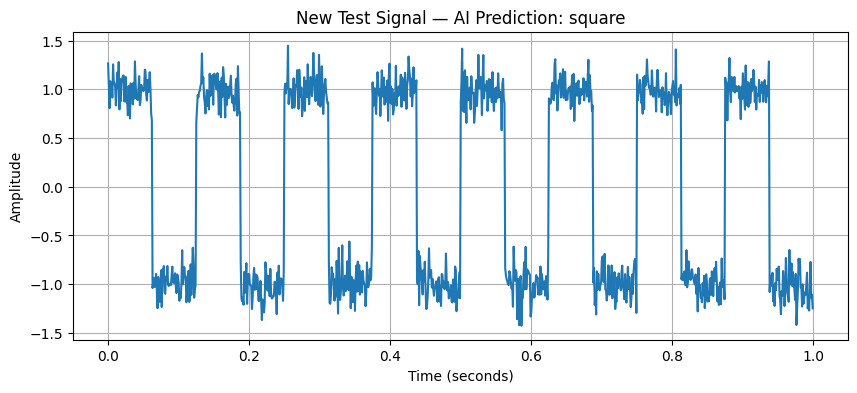

In [9]:
# Test the trained AI on a new signal

test_frequency = 8
test_time = np.arange(0, 1, 1/fs)

new_signal = square(2 * np.pi * test_frequency * test_time)
new_signal = new_signal + np.random.normal(0, 0.15, len(test_time))

features = [[
    np.mean(new_signal),
    np.std(new_signal),
    np.sqrt(np.mean(new_signal**2)),
    np.max(new_signal),
    np.min(new_signal),
    np.mean(np.abs(new_signal))
]]

prediction = model.predict(features)[0]

print("AI Prediction:", prediction)
print("Actual Signal: square")
print("Prediction Correct:", prediction == "square")

plt.figure(figsize=(10, 4))
plt.plot(test_time, new_signal)
plt.title(f"New Test Signal — AI Prediction: {prediction}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

In [11]:
print("Signal Intelligence Dashboard")
print("Dashboard is running successfully!")

Signal Intelligence Dashboard
Dashboard is running successfully!


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import square, sawtooth
import ipywidgets as widgets
from IPython.display import display, clear_output

# Signal Intelligence Dashboard
signal_selector = widgets.Dropdown(
    options=["sine", "square", "triangle"],
    value="sine",
    description="Signal:"
)

noise_slider = widgets.FloatSlider(
    value=0.15,
    min=0,
    max=0.5,
    step=0.05,
    description="Noise:"
)

run_button = widgets.Button(
    description="Analyze Signal",
    button_style="success"
)

output_area = widgets.Output()

def analyze_signal(b):
    with output_area:
        clear_output(wait=True)

        fs = 1000
        t = np.arange(0, 1, 1/fs)
        frequency = 5

        selected = signal_selector.value

        if selected == "sine":
            original = np.sin(2 * np.pi * frequency * t)
        elif selected == "square":
            original = square(2 * np.pi * frequency * t)
        else:
            original = sawtooth(
                2 * np.pi * frequency * t, 0.5
            )

        noisy = original + np.random.normal(
            0, noise_slider.value, len(t)
        )

        # FFT analysis
        spectrum = np.abs(np.fft.rfft(noisy))
        frequencies = np.fft.rfftfreq(len(noisy), 1/fs)
        dominant_frequency = frequencies[
            np.argmax(spectrum[1:]) + 1
        ]

        print("SIGNAL INTELLIGENCE DASHBOARD")
        print("-----------------------------")
        print("Selected signal:", selected)
        print(f"Dominant frequency: {dominant_frequency:.2f} Hz")
        print(f"Noise level: {noise_slider.value}")

        fig, axes = plt.subplots(3, 1, figsize=(10, 9))

        axes[0].plot(t, original)
        axes[0].set_title("Original Signal")
        axes[0].set_ylabel("Amplitude")
        axes[0].grid(True)

        axes[1].plot(t, noisy)
        axes[1].set_title("Signal with Noise")
        axes[1].set_ylabel("Amplitude")
        axes[1].grid(True)

        axes[2].plot(frequencies, spectrum)
        axes[2].set_xlim(0, 50)
        axes[2].set_title("FFT Frequency Spectrum")
        axes[2].set_xlabel("Frequency (Hz)")
        axes[2].set_ylabel("Magnitude")
        axes[2].grid(True)

        plt.tight_layout()
        plt.show()

run_button.on_click(analyze_signal)

display(
    signal_selector,
    noise_slider,
    run_button,
    output_area
)

Dropdown(description='Signal:', options=('sine', 'square', 'triangle'), value='sine')

FloatSlider(value=0.15, description='Noise:', max=0.5, step=0.05)

Button(button_style='success', description='Analyze Signal', style=ButtonStyle())

Output()

AI-Based Signal Intelligence System

Project Overview

The AI-Based Signal Intelligence System analyzes electrical signals using Python and Machine Learning techniques. It generates different types of signals, adds noise, filters unwanted noise, and analyzes frequency components using Fast Fourier Transform (FFT).

Objectives

- Generate sine and square signals.
- Add and analyze noise.
- Perform digital signal filtering.
- Analyze frequency components using FFT.
- Classify signals using a Machine Learning model.

Tools and Technologies

- Python
- Google Colab
- NumPy and Matplotlib
- SciPy
- Scikit-learn

Current Results

- Signal visualization and noise analysis.
- FFT frequency spectrum.
- Signal classification with approximately 98.33% test accuracy in the current experiment.

Note: The accuracy is based on the current simulated dataset and does not guarantee the same performance on real-world signals.

from scipy.signal import butter, filtfilt

# Design a low-pass digital filter
cutoff_frequency = 10
nyquist_frequency = fs / 2

b, a = butter(
    4,
    cutoff_frequency / nyquist_frequency,
    btype="low"
)

cleaned_signal = filtfilt(b, a, noisy_signal)

# Compare original, noisy, and filtered signals
plt.figure(figsize=(12, 5))
plt.plot(t, signal, label="Original Signal")
plt.plot(t, noisy_signal, alpha=0.35, label="Noisy Signal")
plt.plot(t, cleaned_signal, label="Filtered Signal", linewidth=2)

plt.title("Signal Intelligence - Noise Filtering")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()